In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
RNG_SEEDS = list(range(10))   # 10 次不同切分
pd.set_option("display.width", 120)

# 图里的中文不乱码
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# ---------------- 数据位置----------------
DATA_DIR = Path(r"C:\Users\Lenovo\Downloads\第3章 在线学习\数据集")

if not (DATA_DIR / "Wheat seeds.csv").exists():          
    hits = list((Path.home() / "Downloads").glob("*/数据集/Wheat seeds.csv"))
    if hits:
        DATA_DIR = hits[0].parent

print("工作目录：", Path.cwd())
print("数据目录：", DATA_DIR)
assert (DATA_DIR / "Wheat seeds.csv").exists(), "路径不对，改上面的 DATA_DIR"

# ---------------- 读 Wheat seeds ----------------
seeds = pd.read_csv(DATA_DIR / "Wheat seeds.csv")
seeds.columns = [c.strip() for c in seeds.columns]

FEATURES = ["Area", "Perimeter", "Compactness", "Kernel.Length",
            "Kernel.Width", "Asymmetry.Coeff", "Kernel.Groove"]
TARGET = "Type"

X_all = seeds[FEATURES].to_numpy(float)
y_all = seeds[TARGET].astype(int).to_numpy()
CLASSES = np.unique(y_all)

print(f"样本数 {len(seeds)}，特征数 {len(FEATURES)}，类别 {CLASSES.tolist()}")
print("各类样本数：", seeds[TARGET].value_counts().sort_index().to_dict())
display(seeds.head())

stat = seeds[FEATURES].describe().T[["count", "mean", "std", "min", "50%", "max"]]
stat.columns = ["样本数", "均值", "标准差", "最小值", "中位数", "最大值"]
display(stat.round(3))

工作目录： C:\Users\Lenovo
数据目录： C:\Users\Lenovo\Downloads\第3章 在线学习\数据集
样本数 199，特征数 7，类别 [1, 2, 3]
各类样本数： {1: 66, 2: 68, 3: 65}


,Area,Perimeter,Compactness,Kernel.Length,Kernel.Width,Asymmetry.Coeff,Kernel.Groove,Type
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


,样本数,均值,标准差,最小值,中位数,最大值
Area,199.0,14.919,2.920,10.590,14.430,21.180
Perimeter,199.0,14.596,1.310,12.410,14.370,17.250
Compactness,199.0,0.871,0.023,0.808,0.873,0.918
Kernel.Length,199.0,5.643,0.444,4.899,5.541,6.675
Kernel.Width,199.0,3.266,0.378,2.630,3.245,4.033
Asymmetry.Coeff,199.0,3.699,1.471,0.765,3.631,8.315
Kernel.Groove,199.0,5.421,0.493,4.519,5.228,6.550


In [3]:
def phi(x):
    """特征向量末尾补 1，用来吸收偏置 b"""
    x = np.atleast_2d(np.asarray(x, float))
    return np.hstack([x, np.ones((x.shape[0], 1))])


class BaseOnline:
    """二分类在线学习算法的最小接口：来一个样本就 update 一次"""

    def fit(self, X, y):
        for xi, yi in zip(X, y):
            self.update(xi, yi)
        return self

    def update(self, x, y):
        raise NotImplementedError

    def decision(self, X):
        raise NotImplementedError

    def predict(self, X):
        return np.where(self.decision(X) >= 0, 1, -1)


class Perceptron(BaseOnline):
    """算法 3-1：分错才更新，w ← w + y·x"""
    name = "感知机"

    def __init__(self, n_features):
        self.w = np.zeros(n_features + 1)

    def decision(self, X):
        return phi(X) @ self.w

    def update(self, x, y):
        p = np.append(np.asarray(x, float), 1.0)
        if y * (self.w @ p) <= 0:              # 损失 max{0, -y·wᵀx} > 0 才更新
            self.w = self.w + y * p


class PA(BaseOnline):
    """算法 3-3：τ = max{0, 1 - y·wᵀx} / ‖x‖²"""
    name = "PA"

    def __init__(self, n_features):
        self.w = np.zeros(n_features + 1)

    def decision(self, X):
        return phi(X) @ self.w

    def update(self, x, y):
        p = np.append(np.asarray(x, float), 1.0)
        hinge = max(0.0, 1.0 - y * (self.w @ p))
        if hinge > 0.0:
            tau = hinge / (p @ p + 1e-12)      # 教材的 ℓ/‖x‖²，注意是平方
            self.w = self.w + tau * y * p


class NORMA(BaseOnline):
    """算法 3-4：核化 + Hinge + L2 正则 + 有限内存积极集

    f(x) = Σ_{j∈S} α_j K(x_j, x)
    每步先让旧系数收缩 α ← (1-ηλ)α；若 y·f(x) ≤ 1，则新增 α_new = η·y；
    积极集超过 budget 就丢弃最早的样本。
    """
    name = "NORMA"

    def __init__(self, eta=0.3, lam=1e-3, gamma=0.1, budget=128):
        self.eta, self.lam, self.gamma, self.budget = eta, lam, gamma, budget
        self.S, self.a = [], []

    def _kernel(self, A, B):
        d = (A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2.0 * A @ B.T
        return np.exp(-self.gamma * np.maximum(d, 0.0))     # 高斯核

    def decision(self, X):
        X = np.atleast_2d(np.asarray(X, float))
        if not self.S:
            return np.zeros(X.shape[0])
        return self._kernel(X, np.asarray(self.S)) @ np.asarray(self.a)

    def update(self, x, y):
        f = self.decision(x)[0] if self.a else 0.0
        if self.a:                                   # 正则项：整体收缩
            decay = 1.0 - self.eta * self.lam
            self.a = [ai * decay for ai in self.a]
        if y * f <= 1.0:                             # Hinge 次梯度
            self.S.append(np.asarray(x, float))
            self.a.append(self.eta * y)
            if len(self.S) > self.budget:            # 积极集满，丢最早的
                self.S.pop(0)
                self.a.pop(0)


# ---------------- 自检：先打乱，再按位置切 ----------------
mask = y_all != 3                                    # 只取 1、2 两类做二分类
Xb = (X_all[mask] - X_all[mask].mean(0)) / X_all[mask].std(0)
yb = np.where(y_all[mask] == 1, 1, -1)

rng = np.random.default_rng(0)
idx = rng.permutation(len(Xb))                       # 关键：这份数据按类别排序，必须先打乱
Xb, yb = Xb[idx], yb[idx]
n_tr = int(0.7 * len(Xb))

print("训练集标签分布:", np.unique(yb[:n_tr], return_counts=True))
print("测试集标签分布:", np.unique(yb[n_tr:], return_counts=True))

for cls in [Perceptron, PA, NORMA]:
    model = cls(Xb.shape[1]).fit(Xb[:n_tr], yb[:n_tr])
    acc = (model.predict(Xb[n_tr:]) == yb[n_tr:]).mean()
    print(f"{model.name:>4}  测试准确率 {acc:.3f}")

训练集标签分布: (array([-1,  1]), array([47, 46]))
测试集标签分布: (array([-1,  1]), array([21, 20]))
 感知机  测试准确率 0.927
  PA  测试准确率 0.951
NORMA  测试准确率 0.951


In [4]:
class OvR:
    """一对多：每类训练一个「本类 vs 其余」，预测取决策值最大的类"""

    def __init__(self, factory, classes):
        self.factory = factory
        self.classes = np.asarray(classes)

    def fit(self, X, y):
        self.models = [self.factory().fit(X, np.where(y == c, 1, -1)) for c in self.classes]
        return self

    def score(self, X):
        return np.column_stack([m.decision(X) for m in self.models])

    def predict(self, X):
        return self.classes[self.score(X).argmax(axis=1)]

    def update(self, x, y):
        for c, m in zip(self.classes, self.models):
            m.update(x, 1 if y == c else -1)


class OvO:
    """两两配对：3 个二分类器投票，票数相同用边际和打破平局"""

    def __init__(self, factory, classes):
        self.factory = factory
        self.classes = np.asarray(classes)

    def fit(self, X, y):
        self.models = {}
        for i, a in enumerate(self.classes):
            for b in self.classes[i + 1:]:
                mask = (y == a) | (y == b)
                self.models[(a, b)] = self.factory().fit(X[mask], np.where(y[mask] == a, 1, -1))
        return self

    def predict(self, X):
        k = len(self.classes)
        votes = np.zeros((len(X), k))
        margin = np.zeros((len(X), k))
        for (a, b), m in self.models.items():
            d = m.decision(X)
            ia = int(np.where(self.classes == a)[0][0])
            ib = int(np.where(self.classes == b)[0][0])
            win = d >= 0
            votes[win, ia] += 1
            votes[~win, ib] += 1
            margin[:, ia] += np.clip(d, 0, None)
            margin[:, ib] += np.clip(-d, 0, None)
        return self.classes[(votes + 1e-3 * margin).argmax(axis=1)]

    def update(self, x, y):
        for (a, b), m in self.models.items():
            if y == a:
                m.update(x, 1)
            elif y == b:
                m.update(x, -1)


WRAPPERS = {"OvR": OvR, "OvO": OvO}

# ---------------- 评测工具 ----------------
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

NORMA_CFG = dict(eta=0.3, lam=1e-3, gamma=0.1, budget=128)


def make_algo(name, n_features):
    if name == "感知机":
        return Perceptron(n_features)
    if name == "PA":
        return PA(n_features)
    if name == "NORMA":
        return NORMA(**NORMA_CFG)
    raise ValueError(name)


def split_once(seed, test_size=0.30):
    """按类别分层切分，返回训练/测试的下标"""
    return train_test_split(np.arange(len(y_all)), test_size=test_size,
                            random_state=seed, stratify=y_all)


def inject_noise(y, ratio, seed, classes=CLASSES):
    """随机挑 ratio 比例的样本，把标签改成另一个类别（第 6 格用）"""
    y = np.array(y, copy=True)
    n = int(round(ratio * len(y)))
    if n == 0:
        return y
    rng = np.random.default_rng(10_000 + seed)
    for i in rng.choice(len(y), size=n, replace=False):
        y[i] = rng.choice([c for c in classes if c != y[i]])
    return y


def evaluate(algo, wrapper, seed, noise_ratio=0.0):
    """一次完整实验：切分 → 标准化 → 注噪声 → 流式训练 → 干净测试集评估"""
    tr, te = split_once(seed)
    Xtr, Xte = X_all[tr], X_all[te]
    scaler = StandardScaler().fit(Xtr)              # 标准化参数只用训练集估计
    Xtr, Xte = scaler.transform(Xtr), scaler.transform(Xte)
    ytr = inject_noise(y_all[tr], noise_ratio, seed)
    yte = y_all[te]

    model = WRAPPERS[wrapper](lambda: make_algo(algo, Xtr.shape[1]), CLASSES).fit(Xtr, ytr)
    pred = model.predict(Xte)
    return float((pred == yte).mean()), pred, yte


# ---------------- 自检：单次切分跑一遍 ----------------
acc, pred, true = evaluate("PA", "OvR", seed=0)
print(f"PA + OvR 单次切分准确率：{acc:.3f}")

PA + OvR 单次切分准确率：0.983


双月数据： (62, 2) 类别分布： {np.int64(-1): np.int64(30), np.int64(1): np.int64(32)}


,本实现,标准差,教材值
NORMA,0.932,0.070,0.789
PA,0.905,0.082,0.895
感知机,0.932,0.043,0.692


图片已保存： C:\Users\Lenovo\Downloads\第3章 在线学习\图1_双月数据与PA边界.png


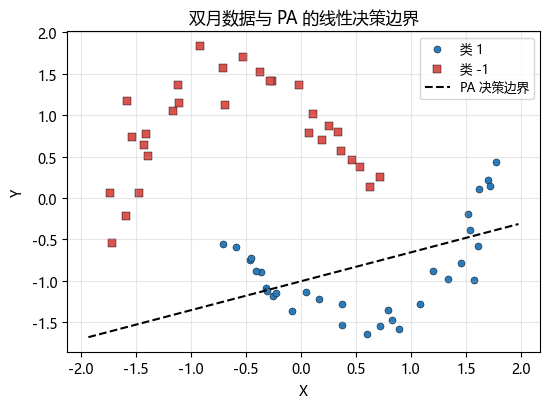

In [5]:
# ---------------- 任务 1：双月数据集 ----------------
moon = pd.read_csv(DATA_DIR / "moon_data.csv")
Xm = moon[["X", "Y"]].to_numpy(float)
ym = moon["Label"].to_numpy(int)
print("双月数据：", Xm.shape, "类别分布：", dict(zip(*np.unique(ym, return_counts=True))))

moon_rows = []
for seed in RNG_SEEDS:
    Xtr, Xte, ytr, yte = train_test_split(Xm, ym, test_size=0.3,
                                          random_state=seed, stratify=ym)
    for name in ["感知机", "PA", "NORMA"]:
        m = make_algo(name, 2).fit(Xtr, ytr)
        moon_rows.append({"算法": name, "seed": seed, "acc": (m.predict(Xte) == yte).mean()})

moon_df = pd.DataFrame(moon_rows)
book = pd.Series({"感知机": 0.692, "PA": 0.895, "NORMA": 0.789}, name="教材值")
moon_sum = (moon_df.groupby("算法")["acc"].agg(["mean", "std"])
            .rename(columns={"mean": "本实现", "std": "标准差"}))
display(pd.concat([moon_sum, book], axis=1).round(3))

# ---------------- 画决策边界，并保存 ----------------
FIG_DIR = DATA_DIR.parent                       # = ...\第3章 在线学习
FIG_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(5.6, 4.2))
for lab, mk, col in [(1, "o", "#2b7bba"), (-1, "s", "#d9534f")]:
    sel = ym == lab
    ax.scatter(Xm[sel, 0], Xm[sel, 1], marker=mk, s=26, c=col,
               edgecolors="k", linewidths=0.3, label=f"类 {lab}")

w = PA(2).fit(Xm, ym).w                          # 用全部样本画一条示意边界
xx = np.linspace(Xm[:, 0].min() - 0.2, Xm[:, 0].max() + 0.2, 100)
ax.plot(xx, -(w[0] * xx + w[2]) / (w[1] if abs(w[1]) > 1e-9 else 1e-9),
        "k--", lw=1.5, label="PA 决策边界")

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title("双月数据与 PA 的线性决策边界")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()

out = FIG_DIR / "图1_双月数据与PA边界.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
print("图片已保存：", out)
plt.show()

In [6]:
from itertools import product
import numpy as np
# ---------------- 0) 先记下默认配置的成绩作基线 ----------------
NORMA_CFG = dict(eta=0.3, lam=1e-3, gamma=0.1, budget=128)
base = np.mean([evaluate("NORMA", "OvR", s)[0] for s in RNG_SEEDS[:5]])
print(f"默认配置基线（5 个种子平均）：{base:.4f}")

# ---------------- 1) 粗网格搜索 ----------------
grid = {"eta": [0.1, 0.3, 1.0],          # 学习率
        "lam": [1e-3, 1e-2, 1e-1],       # 正则化强度
        "gamma": [0.05, 0.1, 0.3, 1.0]}  # 高斯核带宽

rows = []
for eta, lam, gamma in product(grid["eta"], grid["lam"], grid["gamma"]):
    NORMA_CFG = dict(eta=eta, lam=lam, gamma=gamma, budget=128)
    accs = [evaluate("NORMA", "OvR", s)[0] for s in RNG_SEEDS[:5]]
    rows.append({"eta": eta, "lam": lam, "gamma": gamma,
                 "acc": float(np.mean(accs)), "std": float(np.std(accs))})

tune = pd.DataFrame(rows).sort_values("acc", ascending=False).reset_index(drop=True)
display(tune.round(4))

# ---------------- 2) 取最优，覆盖全局配置 ----------------
best = tune.iloc[0]
NORMA_CFG = dict(eta=float(best["eta"]), lam=float(best["lam"]),
                 gamma=float(best["gamma"]), budget=128)
print("选定配置：", NORMA_CFG)
print(f"调参后：{best['acc']:.4f}  相对默认 {best['acc'] - base:+.4f}")

默认配置基线（5 个种子平均）：0.9167


,eta,lam,gamma,acc,std
0,1.0,0.010,1.00,0.9467,0.0245
1,0.3,0.001,1.00,0.9467,0.0221
2,0.1,0.100,1.00,0.9467,0.0194
3,0.1,0.100,0.30,0.9467,0.0194
4,0.3,0.010,1.00,0.9433,0.0226
5,0.1,0.010,1.00,0.9433,0.0226
6,1.0,0.001,1.00,0.9433,0.0271
7,0.1,0.001,1.00,0.9433,0.0226
8,0.1,0.001,0.30,0.9400,0.0226
9,0.3,0.001,0.30,0.9367,0.0340


选定配置： {'eta': 1.0, 'lam': 0.01, 'gamma': 1.0, 'budget': 128}
调参后：0.9467  相对默认 +0.0300


60 次实验（10 种子 × 3 算法 × 2 包装）的准确率：


,mean_OvO,mean_OvR,std_OvO,std_OvR
算法,,,,
感知机,0.9050,0.9017,0.0550,0.0705
PA,0.9400,0.9317,0.0402,0.0474
NORMA,0.9533,0.9567,0.0219,0.0225


最优组合：NORMA + OvR，平均准确率 0.9567
图片已保存： C:\Users\Lenovo\Downloads\第3章 在线学习\图2_三算法对比.png


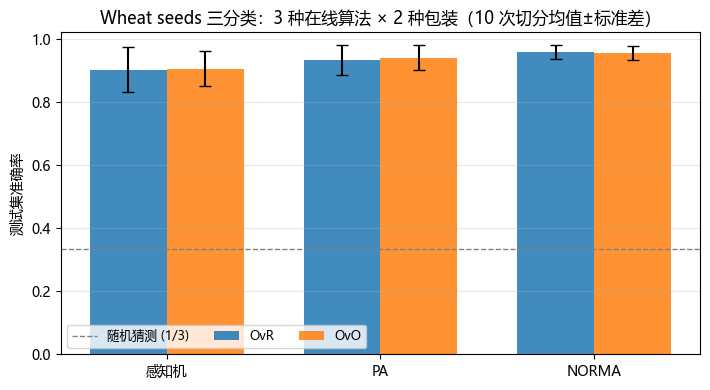

In [6]:
ALGOS = ["感知机", "PA", "NORMA"]

res = []
for seed in RNG_SEEDS:                 # 10 个种子
    for algo in ALGOS:                 # 3 个算法
        for wrapper in ["OvR", "OvO"]: # 2 种包装
            acc, _, _ = evaluate(algo, wrapper, seed)
            res.append({"seed": seed, "算法": algo, "包装": wrapper, "acc": acc})

res = pd.DataFrame(res)

summary = res.groupby(["算法", "包装"])["acc"].agg(["mean", "std"]).unstack("包装")
summary.columns = [f"{stat}_{wrap}" for stat, wrap in summary.columns]
summary = summary.reindex(ALGOS)
print("60 次实验（10 种子 × 3 算法 × 2 包装）的准确率：")
display(summary.round(4))

pair_means = res.groupby(["算法", "包装"])["acc"].mean()
print(f"最优组合：{pair_means.idxmax()[0]} + {pair_means.idxmax()[1]}，"
      f"平均准确率 {pair_means.max():.4f}")

# ---------------- 柱状图 ----------------
fig, ax = plt.subplots(figsize=(7.2, 4.0))
x = np.arange(len(ALGOS))
w = 0.36
for k, wrapper in enumerate(["OvR", "OvO"]):
    sub = (res[res["包装"] == wrapper].groupby("算法")["acc"]
           .agg(["mean", "std"]).reindex(ALGOS))
    ax.bar(x + (k - 0.5) * w, sub["mean"], w, yerr=sub["std"], capsize=4,
           label=wrapper, alpha=0.85)
ax.set_xticks(x, ALGOS)
ax.set_ylabel("测试集准确率")
ax.set_ylim(0, 1.02)
ax.set_title("Wheat seeds 三分类：3 种在线算法 × 2 种包装（10 次切分均值±标准差）")
ax.axhline(1 / 3, ls="--", c="grey", lw=1, label="随机猜测 (1/3)")
ax.legend(ncol=3, fontsize=9)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()

out = FIG_DIR / "图2_三算法对比.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
print("图片已保存：", out)
plt.show()

最优组合：NORMA + OvR，平均准确率 0.9567
图片已保存： C:\Users\Lenovo\Downloads\第3章 在线学习\图3_混淆矩阵.png


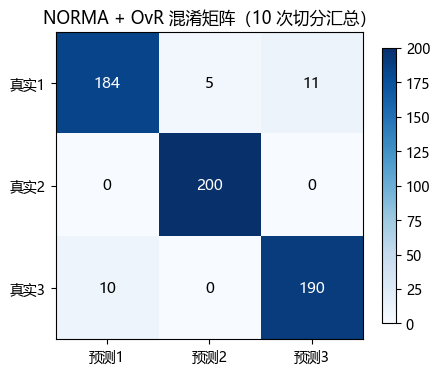

,预测1,预测2,预测3,召回率
真实1,184,5,11,0.92
真实2,0,200,0,1.00
真实3,10,0,190,0.95


类 1：精确率 0.948，召回率 0.920
类 2：精确率 0.976，召回率 1.000
类 3：精确率 0.945，召回率 0.950


In [7]:
from sklearn.metrics import confusion_matrix

pair_means = res.groupby(["算法", "包装"])["acc"].mean()
best_algo, best_wrapper = pair_means.idxmax()
print(f"最优组合：{best_algo} + {best_wrapper}，平均准确率 {pair_means.max():.4f}")

# 把 10 次切分的测试集预测汇总成一个混淆矩阵
cm = np.zeros((len(CLASSES), len(CLASSES)), dtype=int)
for seed in RNG_SEEDS:
    _, pred, true = evaluate(best_algo, best_wrapper, seed)
    cm += confusion_matrix(true, pred, labels=CLASSES)

fig, ax = plt.subplots(figsize=(4.6, 4.0))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASSES)), [f"预测{c}" for c in CLASSES])
ax.set_yticks(range(len(CLASSES)), [f"真实{c}" for c in CLASSES])
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=11)
ax.set_title(f"{best_algo} + {best_wrapper} 混淆矩阵（10 次切分汇总）")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()

out = FIG_DIR / "图3_混淆矩阵.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
print("图片已保存：", out)
plt.show()

# 逐类看召回率和精确率
cm_df = pd.DataFrame(cm, index=[f"真实{c}" for c in CLASSES],
                     columns=[f"预测{c}" for c in CLASSES])
cm_df["召回率"] = (cm.diagonal() / cm.sum(axis=1)).round(3)
display(cm_df)

for i, c in enumerate(CLASSES):
    prec = cm[i, i] / cm[:, i].sum()
    print(f"类 {c}：精确率 {prec:.3f}，召回率 {cm[i, i] / cm[i].sum():.3f}")

图片已保存： C:\Users\Lenovo\Downloads\第3章 在线学习\图4_在线准确率曲线.png


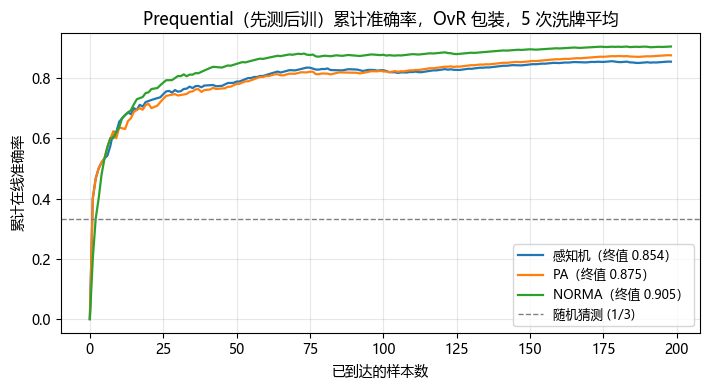

终值： {'感知机': np.float64(0.8543), 'PA': np.float64(0.8754), 'NORMA': np.float64(0.9045)}
前 20 个样本的平均准确率：
  感知机: 前20个 0.720 → 全部 0.854
  PA: 前20个 0.710 → 全部 0.875
  NORMA: 前20个 0.750 → 全部 0.905


In [8]:
def prequential_curve(algo, wrapper, seed):
    """第 t 个样本到达时，只用前 t-1 个样本训练出的模型预测它，然后立刻更新"""
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(y_all))
    Xs = StandardScaler().fit_transform(X_all)[order]   # 只用特征，不涉及标签
    ys = y_all[order]

    model = WRAPPERS[wrapper](lambda: make_algo(algo, Xs.shape[1]), CLASSES)
    model.fit(Xs[:0], ys[:0])          # 空模型起步，第一个样本也得靠“猜”

    flags = []
    for x, y in zip(Xs, ys):
        flags.append(model.predict(x[None, :])[0] == y)   # 先测
        model.update(x, y)                                # 后训
    return np.cumsum(flags) / np.arange(1, len(flags) + 1)


fig, ax = plt.subplots(figsize=(7.2, 4.0))
final = {}
for algo in ALGOS:
    curves = np.array([prequential_curve(algo, "OvR", s) for s in RNG_SEEDS[:5]])
    mean_curve = curves.mean(axis=0)
    final[algo] = mean_curve[-1]
    ax.plot(mean_curve, lw=1.6, label=f"{algo}（终值 {mean_curve[-1]:.3f}）")

ax.axhline(1 / 3, ls="--", c="grey", lw=1, label="随机猜测 (1/3)")
ax.set_xlabel("已到达的样本数")
ax.set_ylabel("累计在线准确率")
ax.set_title("Prequential（先测后训）累计准确率，OvR 包装，5 次洗牌平均")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()

out = FIG_DIR / "图4_在线准确率曲线.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
print("图片已保存：", out)
plt.show()

print("终值：", {k: round(v, 4) for k, v in final.items()})
print("前 20 个样本的平均准确率：")
for algo in ALGOS:
    c = np.array([prequential_curve(algo, "OvR", s) for s in RNG_SEEDS[:5]]).mean(axis=0)
    print(f"  {algo}: 前20个 {c[19]:.3f} → 全部 {c[-1]:.3f}")

干净测试集上的准确率（10 次切分均值）：


算法,感知机,PA,NORMA
0%,0.9017,0.9317,0.9567
5%,0.8667,0.8667,0.9533
10%,0.8567,0.8317,0.9267
15%,0.7850,0.7650,0.9367
20%,0.6333,0.6150,0.9233
30%,0.6517,0.6500,0.8700


相对 0% 噪声的下降：


,感知机_相对0%,PA_相对0%,NORMA_相对0%
0%,0.0000,0.0000,0.0000
5%,-0.0350,-0.0650,-0.0034
10%,-0.0450,-0.1000,-0.0300
15%,-0.1167,-0.1667,-0.0200
20%,-0.2684,-0.3167,-0.0334
30%,-0.2500,-0.2817,-0.0867


图片已保存： C:\Users\Lenovo\Downloads\第3章 在线学习\图5_标签噪声鲁棒性.png


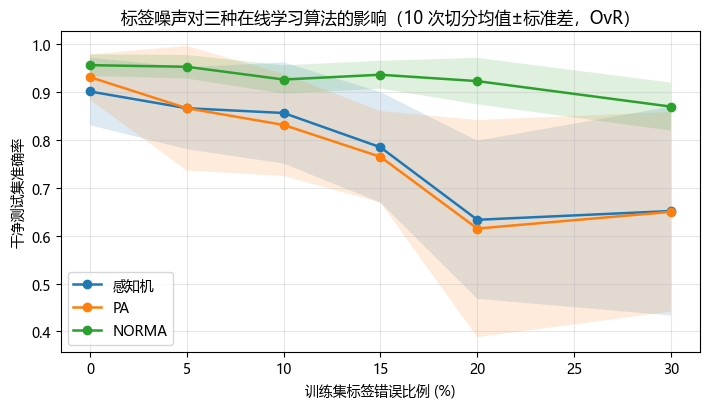

=== 各噪声档位下的表现 ===
噪声   0%：最优 NORMA 0.9567 | 感知机 0.9017  PA 0.9317  NORMA 0.9567
噪声   5%：最优 NORMA 0.9533 | 感知机 0.8667  PA 0.8667  NORMA 0.9533
噪声  10%：最优 NORMA 0.9267 | 感知机 0.8567  PA 0.8317  NORMA 0.9267
噪声  15%：最优 NORMA 0.9367 | 感知机 0.7850  PA 0.7650  NORMA 0.9367
噪声  20%：最优 NORMA 0.9233 | 感知机 0.6333  PA 0.6150  NORMA 0.9233
噪声  30%：最优 NORMA 0.8700 | 感知机 0.6517  PA 0.6500  NORMA 0.8700


In [9]:
RATIOS = [0.0, 0.05, 0.10, 0.15, 0.20, 0.30]      # 训练集标签错误比例

noise_rows = []
for ratio in RATIOS:
    for algo in ALGOS:
        for seed in RNG_SEEDS:
            acc, _, _ = evaluate(algo, "OvR", seed, noise_ratio=ratio)
            noise_rows.append({"ratio": ratio, "算法": algo, "seed": seed, "acc": acc})

noise = pd.DataFrame(noise_rows)
noise_sum = noise.groupby(["算法", "ratio"])["acc"].agg(["mean", "std"]).reset_index()

table = (noise_sum.pivot(index="ratio", columns="算法", values="mean")
         .reindex(ALGOS, axis=1).round(4))
table.index = [f"{r:.0%}" for r in table.index]
print("干净测试集上的准确率（10 次切分均值）：")
display(table)

# 相对无噪声时的下降幅度
drop = table.copy()
for c in drop.columns:
    drop[c] = (drop[c] - drop[c].iloc[0]).round(4)
drop.columns = [f"{c}_相对0%" for c in drop.columns]
print("相对 0% 噪声的下降：")
display(drop)

# ---------------- 曲线图 ----------------
fig, ax = plt.subplots(figsize=(7.2, 4.2))
for algo in ALGOS:
    sub = noise_sum[noise_sum["算法"] == algo].sort_values("ratio")
    ax.plot(sub["ratio"] * 100, sub["mean"], marker="o", label=algo, lw=1.8)
    ax.fill_between(sub["ratio"] * 100, sub["mean"] - sub["std"],
                    sub["mean"] + sub["std"], alpha=0.15)
ax.set_xlabel("训练集标签错误比例 (%)")
ax.set_ylabel("干净测试集准确率")
ax.set_title("标签噪声对三种在线学习算法的影响（10 次切分均值±标准差，OvR）")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()

out = FIG_DIR / "图5_标签噪声鲁棒性.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
print("图片已保存：", out)
plt.show()

# ---------------- 各档位谁最优 ----------------
print("=== 各噪声档位下的表现 ===")
for r in RATIOS:
    row = table.loc[f"{r:.0%}"]
    print(f"噪声 {r:>4.0%}：最优 {row.idxmax()} {row.max():.4f} | "
          + "  ".join(f"{k} {v:.4f}" for k, v in row.items()))

In [10]:
def noise_confusion(algo, ratio):
    cm = np.zeros((len(CLASSES), len(CLASSES)), dtype=int)
    for seed in RNG_SEEDS:
        acc, pred, true = evaluate(algo, "OvR", seed, noise_ratio=ratio)
        cm += confusion_matrix(true, pred, labels=CLASSES)
    return cm


for ratio in [0.0, 0.20, 0.30]:
    print(f"\n===== 噪声 {ratio:.0%} =====")
    for algo in ALGOS:
        cm = noise_confusion(algo, ratio)
        rec = cm.diagonal() / cm.sum(axis=1)
        acc = cm.diagonal().sum() / cm.sum()
        print(f"{algo:>3}  准确率 {acc:.3f}  召回率 "
              + "  ".join(f"类{c}={r:.2f}" for c, r in zip(CLASSES, rec)))


===== 噪声 0% =====
感知机  准确率 0.902  召回率 类1=0.76  类2=0.99  类3=0.95
 PA  准确率 0.932  召回率 类1=0.89  类2=1.00  类3=0.91
NORMA  准确率 0.957  召回率 类1=0.92  类2=1.00  类3=0.95

===== 噪声 20% =====
感知机  准确率 0.633  召回率 类1=0.59  类2=0.69  类3=0.61
 PA  准确率 0.615  召回率 类1=0.67  类2=0.64  类3=0.54
NORMA  准确率 0.923  召回率 类1=0.87  类2=0.97  类3=0.93

===== 噪声 30% =====
感知机  准确率 0.652  召回率 类1=0.65  类2=0.79  类3=0.53
 PA  准确率 0.650  召回率 类1=0.64  类2=0.78  类3=0.54
NORMA  准确率 0.870  召回率 类1=0.83  类2=0.93  类3=0.85
